In [1]:
import gcinfo
import pandas as pd
import matplotlib.pyplot as plt

gcinfo.search_titles(
    query='title:"Gross domestic product per capita"',
    format_filter="CSV",
)


Gross domestic product per capita and other per capita macroeconomic indicators


In [2]:
gcinfo.list_resources(
    gcinfo.search_datasets(
        query='title:"Gross domestic product per capita and other per capita macroeconomic indicators"'
    )["results"][0]
)



=== Gross domestic product per capita and other per capita macroeconomic indicators ===
ID: cd36c2e3-f2ad-4654-8954-25e79a346b36
Org: Statistics Canada | Statistique Canada
Notes: This table contains estimates of gross domestic product per capita and other per capita macroeconomic indicators.<br>...
URL: https://www150.statcan.gc.ca/t1/tbl1/en/tv.action?pid=3610070601
Citation: Statistics Canada. Table 36-10-0706-01 Gross domestic product per capita and other per capita macroeconomic indicators
DOI:      https://doi.org/10.25318/3610070601-eng
  [CSV     ] Dataset
           https://www150.statcan.gc.ca/n1/tbl/csv/36100706-fra.zip
  [CSV     ] Dataset
           https://www150.statcan.gc.ca/n1/tbl/csv/36100706-eng.zip
  [XML     ] Dataset
           https://www150.statcan.gc.ca/n1/tbl/sdmx/36100706-SDMX.zip


In [3]:
# Quarterly gross domestic product per capita, Canada.
df, df_meta = gcinfo.download_zip(
    "https://www150.statcan.gc.ca/n1/tbl/csv/36100706-eng.zip"
)


Using cached file: cache\36100706-eng.zip


In [4]:
real = df[
    (df["GEO"] == "Canada")
    & (df["Estimates"] == "Gross domestic product per capita")
    & (df["Prices"] == "Chained (2017) dollars")
][["REF_DATE", "VALUE"]].copy()
real["Date"] = pd.to_datetime(real["REF_DATE"])
real = real.sort_values("Date")
real["Year"] = real["Date"].dt.year
real = real.rename(columns={"VALUE": "GDP per Capita"})

# Average of the four quarters. A year still in progress is left out.
counts = real.groupby("Year").size()
complete_years = counts[counts == 4].index
annual = (
    real.loc[real["Year"].isin(complete_years)]
    .groupby("Year")["GDP per Capita"]
    .mean()
    .round(0)
    .astype("int64")
    .to_frame()
)
annual


,GDP per Capita
Year,
1981,37329
1982,35718
1983,36264
1984,38042
1985,39479
1986,39925
1987,41028
1988,42274
1989,42526


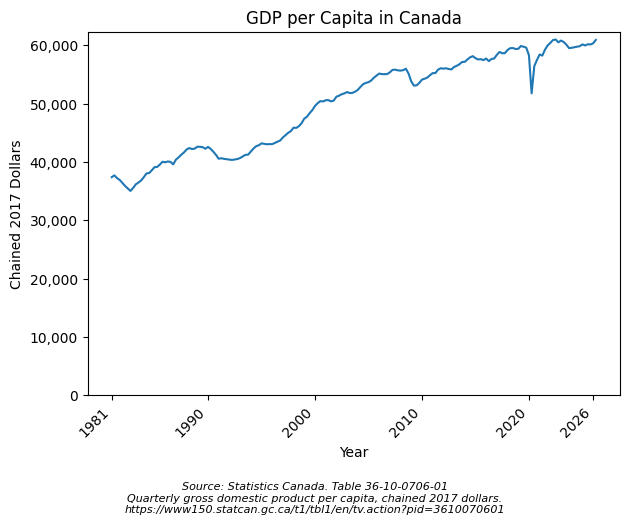

In [5]:
fig, ax = plt.subplots()
ax.plot(real["Date"], real["GDP per Capita"], linestyle="-")
ax.set_title("GDP per Capita in Canada")
ax.set_xlabel("Year")
ax.set_ylabel("Chained 2017 Dollars")
ax.set_ylim(bottom=0)
last_year = int(real["Date"].max().year)
tick_years = [int(real["Date"].min().year)] + list(range(1990, last_year + 1, 10))
if last_year not in tick_years:
    tick_years.append(last_year)
ax.set_xticks([pd.Timestamp(year=year, month=1, day=1) for year in tick_years])
ax.set_xticklabels(tick_years)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda value, _pos: f"{value:,.0f}"))
plt.figtext(
    0.5,
    -0.08,
    "Source: Statistics Canada. Table 36-10-0706-01\n"
    "Quarterly gross domestic product per capita, chained 2017 dollars.\n"
    "https://www150.statcan.gc.ca/t1/tbl1/en/tv.action?pid=3610070601",
    ha="center",
    fontsize=8,
    style="italic",
)
plt.subplots_adjust(bottom=0.36)
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()
